In [1]:
from pathlib import Path
import os, sys

# Auto-set repo root (expects Data/ and predictions/ at root)
cwd = Path.cwd()
REPO_ROOT = None
for parent in [cwd, *cwd.parents]:
    if (parent / "Data").exists() and (parent / "predictions").exists():
        REPO_ROOT = parent
        break
if REPO_ROOT is None:
    REPO_ROOT = cwd
os.chdir(REPO_ROOT)

# Add notebook-local modules to import path
src_candidates = [
    REPO_ROOT / "notebooks",
    REPO_ROOT / "code_repository" / "notebooks",
]
for SRC in src_candidates:
    if SRC.exists() and str(SRC) not in sys.path:
        sys.path.insert(0, str(SRC))
        break
print(f"Working dir: {Path.cwd()}")


Working dir: /mnt/nas/PhD/Code/Ms_paint


In [2]:
from analysis.plot_style import apply_style, save_figure, set_save_dir
FIGURE_ID = "supplementary"
FIG_DIR = set_save_dir(REPO_ROOT, FIGURE_ID)
apply_style()


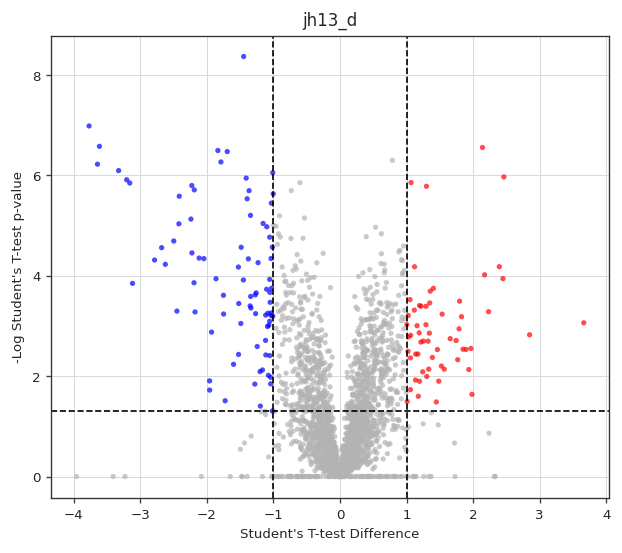

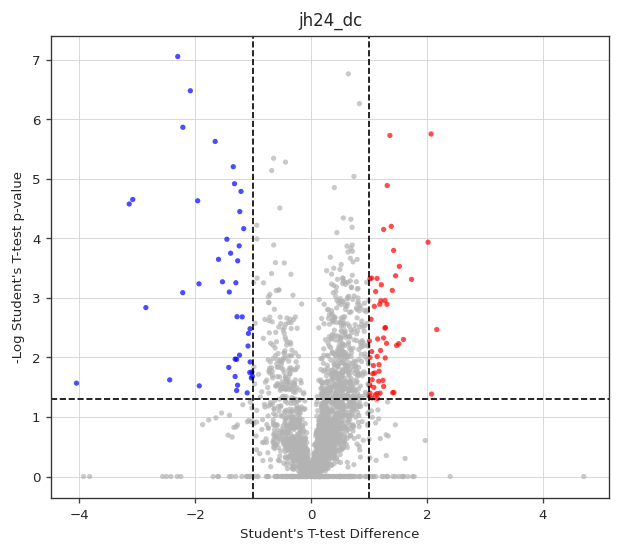

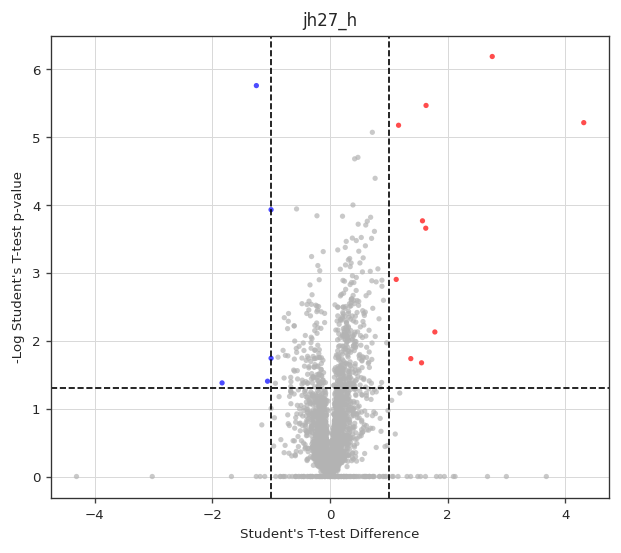

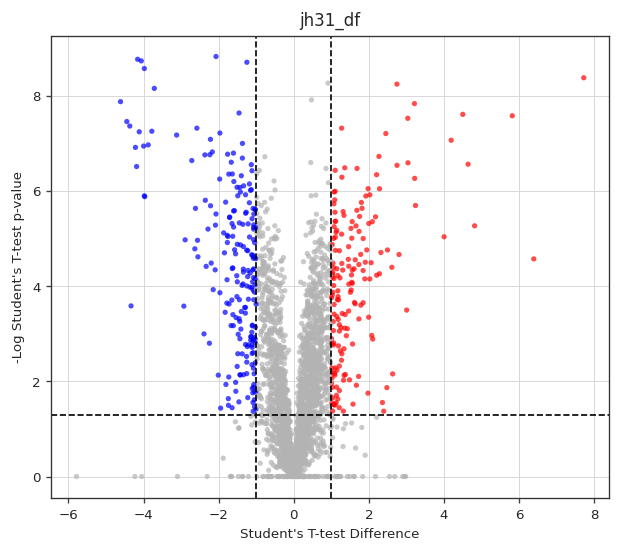

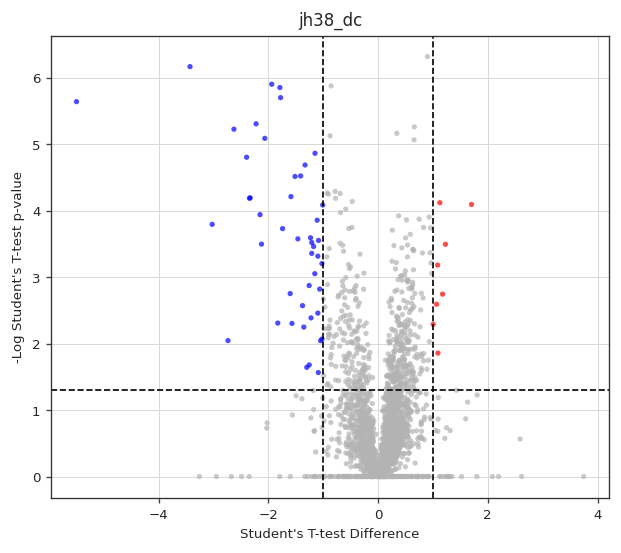

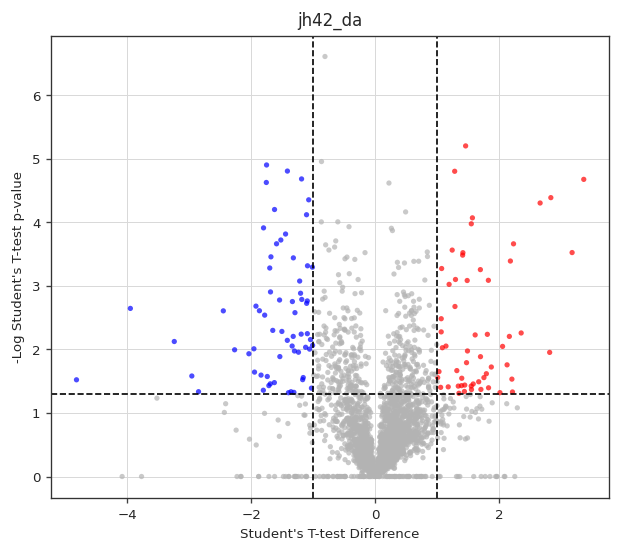

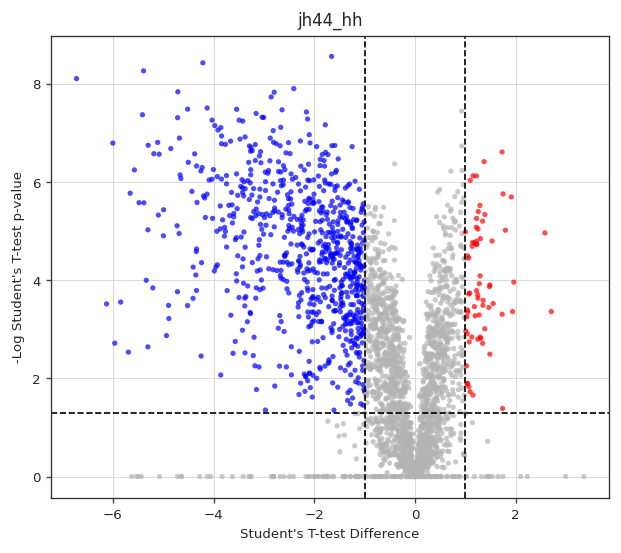

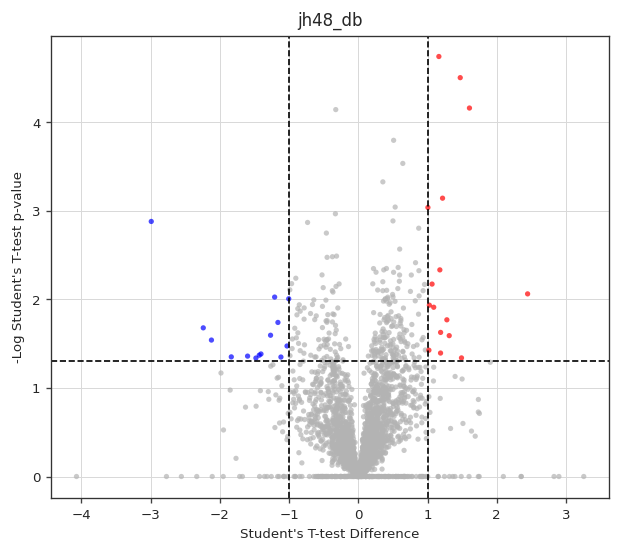

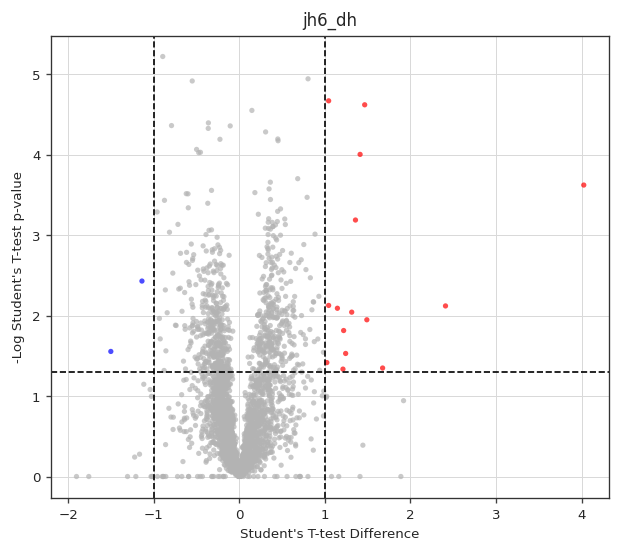

Saved Excel file to: string_analysis/significant_genes.xlsx


In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("string_analysis")
files = sorted(DATA_DIR.glob("*.txt"))

if not files:
    raise FileNotFoundError(f"No .txt files found in {DATA_DIR}")


def find_column(columns, needle):
    matches = [c for c in columns if needle in str(c)]
    return matches[0] if matches else None


def coerce_numeric(series):
    return pd.to_numeric(
        series.astype(str).str.replace(",", ".", regex=False), errors="coerce"
    )


def find_gene_column(columns):
    for name in ["T: Gene name", "T: Genes", "T: Protein.Names", "T: Protein.Ids"]:
        if name in columns:
            return name
    return columns[-1]


sig_up = {}
sig_down = {}

for file_path in files:
    df = pd.read_csv(file_path, sep="	", dtype=str)

    x_col = find_column(df.columns, "N: Student's T-test Difference")
    y_col = find_column(df.columns, "N: -Log Student's T-test p-value")

    if not x_col or not y_col:
        print(f"Skipping {file_path.name}: missing required columns")
        continue

    x = coerce_numeric(df[x_col])
    y = coerce_numeric(df[y_col])
    mask = x.notna() & y.notna()

    x = x[mask]
    y = y[mask]
    df_plot = df.loc[mask].copy()

    gene_col = find_gene_column(df.columns)
    genes = df_plot[gene_col].fillna("").astype(str)

    sig_up_mask = (y > 1.3) & (x > 1)
    sig_down_mask = (y > 1.3) & (x < -1)

    colors = np.full(len(x), "0.7", dtype=object)
    colors[sig_up_mask.to_numpy()] = "red"
    colors[sig_down_mask.to_numpy()] = "blue"

    fig, ax = plt.subplots(figsize=(6, 5), dpi=120)
    ax.scatter(x, y, s=10, c=colors, alpha=0.7, linewidths=0)
    ax.axhline(1.3, color="black", linewidth=1, linestyle="--")
    ax.axvline(1, color="black", linewidth=1, linestyle="--")
    ax.axvline(-1, color="black", linewidth=1, linestyle="--")
    ax.set_title(file_path.stem)
    ax.set_xlabel("Student's T-test Difference")
    ax.set_ylabel("-Log Student's T-test p-value")
    save_figure(plt.gcf(), DATA_DIR / f"{file_path.stem}_volcano_plot.pdf", dpi=300, format="pdf")
    plt.show()
    

    up_genes = sorted(set(g for g in genes[sig_up_mask] if g))
    down_genes = sorted(set(g for g in genes[sig_down_mask] if g))

    sig_up[file_path.stem] = up_genes
    sig_down[file_path.stem] = down_genes


output_path = DATA_DIR / "significant_genes.xlsx"
with pd.ExcelWriter(output_path) as writer:
    for compound in sorted(sig_up.keys()):
        up_series = pd.Series(sig_up[compound], name="upregulated")
        down_series = pd.Series(sig_down[compound], name="downregulated")
        out_df = pd.concat([up_series, down_series], axis=1)
        out_df.to_excel(writer, sheet_name=compound[:31], index=False)

print(f"Saved Excel file to: {output_path}")


In [4]:
import gseapy as gp

up_genes = up_series.tolist()  # DNA damage example

enr = gp.enrichr(
    gene_list=up_genes,
    gene_sets=[
        "KEGG_2019_E_coli",
        "EcoCyc_2018",
        "GO_Biological_Process_2023",
        "RegulonDB_2015"
    ],
    outdir=None
)

enr.results.head()


2026-01-16 15:07:51,816 [WARNING] Input library not found: KEGG_2019_E_coli. Skip
2026-01-16 15:07:51,817 [WARNING] Input library not found: EcoCyc_2018. Skip
2026-01-16 15:07:51,818 [WARNING] Input library not found: RegulonDB_2015. Skip


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes


In [5]:
import requests
import pandas as pd
from io import StringIO

string_api_url = "https://string-db.org/api"
output = "tsv"
method = "enrichment"


def run_string_enrichment(genes, species=511145, caller_identity="moa_proteomics"):
    genes = [g for g in genes if g]
    if not genes:
        return pd.DataFrame()

    params = {
        "identifiers": "%0d".join(genes),
        "species": species,
        "caller_identity": caller_identity,
    }

    response = requests.post(f"{string_api_url}/{output}/{method}", data=params)
    response.raise_for_status()
    return pd.read_csv(StringIO(response.text), sep="	")


string_results = {"up": {}, "down": {}}

for compound in sorted(sig_up.keys()):
    string_results["up"][compound] = run_string_enrichment(sig_up[compound])
    string_results["down"][compound] = run_string_enrichment(sig_down[compound])


output_path = DATA_DIR / "string_enrichment.xlsx"
with pd.ExcelWriter(output_path) as writer:
    for compound in sorted(sig_up.keys()):
        up_df = string_results["up"][compound]
        down_df = string_results["down"][compound]

        up_df.to_excel(writer, sheet_name=f"{compound}_up"[:31], index=False)
        down_df.to_excel(writer, sheet_name=f"{compound}_down"[:31], index=False)

print(f"Saved STRING enrichment to: {output_path}")


Saved STRING enrichment to: string_analysis/string_enrichment.xlsx
